# 12강 실습: '완전'과 '아주'의 출현 환경

"이 과자 **완전** 맛있다", "나 떡볶이 **완전** 좋아해". 그런데 표준국어대사전에서 '완전(完全)'은 **명사**뿐이다(부사는 '완전히'). 오늘은 이 '완전'과 부사 '아주'가 각각 어떤 말 **바로 앞**에 오는지를 11강의 발화 표에서 센다.

**읽을 논문**: 김다미(2021), 부사적 쓰임을 보이는 '완전(完全)'에 대한 통시적 고찰, 《국어학》 97, 439–475. https://doi.org/10.15811/jkl.2021.97.014

- '완전'은 명사로 쓰이다가 명사 앞에서 꾸미는 말(완전 개방)이 되었고, 20세기 초에 동사구 앞의 **completely**(완전¹), 20세기 말에야 형용사 앞의 **very**(완전²)가 나타났다.
- 완전¹은 동작성 서술어(동사)와, 완전²는 상태성 서술어(형용사)와 잘 어울린다. 부사 '완전히'는 완전¹의 자리만 맡는다("노트북이 완전히 망가졌다"는 되지만 "??기분이 완전히 좋다"는 어색하다).
- '아주'도 동사 앞의 completely(16–18세기)에서 형용사 앞의 very(19세기 말)로 같은 길을 먼저 갔다. 논문은 '아주'가 very를 기본 뜻으로 삼을 만큼 나아갔고 '완전'은 그 속도에 미치지 못했다고 본다.
- 논문의 가설(4.2절): '완전'은 '완전히'보다 더 자주 쓰였고, 그래서 뜻이 더 넓어졌다.

**오늘 셀 것** — 2021년 온라인 대화 3백만 발화에서

1. '완전'은 '완전히', '아주'와 비교해 얼마나 자주 쓰이는가?
2. '완전'과 '아주'의 바로 뒤에는 어떤 품사가 오는가?
3. 어떤 말이 '완전'을, 어떤 말이 '아주'를 더 좋아하는가?

**물음을 수로 바꾸기**(조작적 정의). 개념을 '무엇을 어떻게 세는가'로 바꾸어 적는다. 다른 사람이 같은 수를 다시 얻으려면 이것을 적어야 한다.

| 논문의 말 | 오늘 셀 것 |
|---|---|
| 부사적 쓰임의 '완전' | 띄어 쓴 어절 '완전'(1절), 형태소 '완전'(3절) |
| 상태성 서술어 (완전²) | 바로 뒤 형태소가 **형용사** (`VA`, 어근 `XR`) |
| 동작성 서술어 (완전¹) | 바로 뒤 형태소가 **동사** (`VV`) |
| 명사 앞에서 꾸미는 말 | 바로 뒤 형태소가 **체언** (`NNG`, `NNP`, `NP`) |

품사는 뜻의 **어림값**이다. '좋아하다'는 동사지만 "완전 좋아해"는 very다. 어림이 빗나가는 자리도 함께 본다.

**시작하기 전에**

- 이 노트북은 저장소 **맨 위**(`/workspaces/LDS2026`)에 두어야 `data/nikl/…` 경로가 맞는다.
- 11강 노트북이 만든 `data/nikl/utterances.csv`가 있어야 한다. 없으면(Codespace를 새로 만들었다면) 말뭉치 zip을 다시 올리고 `11-json.ipynb`를 [Run All]로 돌린다.
- 그림의 한글이 네모로 나오지 않도록, 노트북을 열기 전에 터미널에서 matplotlib의 글꼴 목록을 지운다. 10강에서 깐 나눔고딕을 새로 찾게 하는 것이다(7강).
- 커밋하기 전에는 [Restart] 후 [Run All]로 위에서 아래까지 한 번에 돌려 본다.

```bash
cd /workspaces/LDS2026
rm -rf ~/.cache/matplotlib
```

## 0. 준비

네 가지를 불러오고 그림의 바탕을 정한다.

- **pandas**: 7강에서 쓴 표 라이브러리
- **seaborn**, **matplotlib**: 7강의 그리기 도구. `set_theme`에 `font='NanumGothic'`을 주면 그림의 한글이 나온다.
- **Kiwi**: 10강의 형태소 분석기(`kiwipiepy`). 분석기는 판이 바뀌면 결과가 바뀐다. 슬라이드의 수는 0.23.2로 얻었다.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from kiwipiepy import Kiwi

kiwi = Kiwi()
sns.set_theme(style='whitegrid', font='NanumGothic')

## 1. 글자로 찾기

11강에서 남긴 발화 표를 다시 읽는다. 빈 발화를 빼고 NFC로 맞춘 2,977,840행이다. 오늘 쓰는 열은 발화를 다듬은 `form` 하나다. 이름이 길어 오늘은 표를 `u`라고 부른다.

In [2]:
u = pd.read_csv('data/nikl/utterances.csv')
print(u.shape)

(2977840, 6)


먼저 글자열 '아주'가 든 발화를 고르고, 그 안에서 '아주'를 품은 낱말을 모두 뽑아 센다.

- `\w`: 글자 하나. 한글, 로마자, 숫자 따위이고 문장 부호와 공백은 아니다.
- `\w*아주\w*`: '아주' 앞뒤로 글자가 몇 개든 붙은 낱말 전체
- `findall`: 맞는 부분을 **모두** 목록으로 돌려준다(8강의 `re.findall`). 칸마다 목록이 드니 `explode`로 펼친다(10·11강).

'놀아주고'(-아 주다), '아주머니', 주식 종목 '아주스틸'도 걸린다. **글자열 '아주'는 낱말 '아주'가 아니다.**

In [3]:
has = u['form'].str.contains('아주')
words = u.loc[has, 'form'].str.findall(r'\w*아주\w*').explode()
print(words.value_counts().head(6))

form
아주      3397
아주그냥      83
아주아주      46
놀아주고      40
아주스틸      33
아주머니      31
Name: count, dtype: int64


**단어 경계** `\b`는 글자(`\w`)와 글자가 아닌 것 사이, 곧 낱말의 앞뒤 끝이다. '완전히'의 '완전' 뒤에는 '히'가 붙어 있어 경계가 아니다.

- `rf'…'`: `r`은 백슬래시를 그대로 두고(8강), `f`는 `{w}` 자리에 값을 넣는다(10강).
- `str.count`: 발화마다 맞은 **횟수**. 모두 더하면 출현 수다.

**첫째 물음의 답**: '완전'은 '완전히'의 약 50배, '아주'의 2.5배다. 논문의 가설이 기대한 쪽과 같다.

In [4]:
for w in ['완전', '완전히', '아주']:
    print(w, u['form'].str.count(rf'\b{w}\b').sum())

완전 8636
완전히 174
아주 3397


`\b`가 놓친 '완전'을 본다. '완전'을 품은 낱말 가운데 '완전' 그 자체가 아닌 것들이다.

- 놓친 것: 완전요, 완전좋아, 완전좋아해요, 이거완전 — 띄어 쓰지 않았다.
- 바르게 뺀 것: 완전히, 완전한 — 다른 낱말이다.

둘 다 '완전' 뒤에 한글이 붙었다. **글자로는 가를 수 없다.** 어디서 끊어지는지는 형태소 분석이 알려 준다(3절). 'ㅋ'도 `\w`라서(9강의 호환 자모) '완전ㅋㅋ'에서도 `\b완전\b`는 맞지 않는다.

In [5]:
words = u['form'].str.findall(r'\w*완전\w*').explode()
print(words[words != '완전'].value_counts().head(6))

form
완전히       174
완전요        70
완전한        32
완전좋아       20
완전좋아해요     18
이거완전       14
Name: count, dtype: int64


## 2. 바로 뒤 어절

괄호로 '완전'·'아주' 바로 뒤의 어절을 잡아 센다.

- `( )`: 괄호(묶음)가 있으면 `findall`은 괄호 안에 맞은 부분만 돌려준다. '완전'과 공백은 버리고 뒤의 어절만 남는다.
- `pd.DataFrame({'완전': wj, '아주': aj})`: '열 이름: Series'의 dict를 주면 낱말이 같은 행끼리 맞추어 붙인다.
- `fillna(0)`: 한쪽에만 나온 어절은 다른 쪽이 `NaN`이다. 0으로 메운다(7강).

In [6]:
wj = u['form'].str.findall(r'\b완전 (\w+)').explode().value_counts()
aj = u['form'].str.findall(r'\b아주 (\w+)').explode().value_counts()
ej = pd.DataFrame({'완전': wj, '아주': aj}).fillna(0).astype(int)
print(ej.sort_values('완전', ascending=False).head(4))

       완전  아주
form         
좋아해요  173  13
많이     58  23
잘      50  59
맛있어요   38   7


어절로 세면 '좋다'가 흩어진다. '좋'으로 시작하는 어절만 242가지다. 10강에서 '영화'로 시작하는 어절이 6,233가지였던 것과 같은 일이다.

게다가 '좋아해요'는 동사 '좋아하다', '좋은'은 형용사 '좋다'다. 어절은 어미까지 달고 있어서 **품사로 묶으려면 형태소로 나누어야** 한다.

In [7]:
good = ej[ej.index.str.startswith('좋')]
print(len(good))
print(good.sort_values('완전', ascending=False).head(5))

242
       완전  아주
form         
좋아해요  173  13
좋아요    34  22
좋아     26  25
좋죠     24   7
좋은     21  52


## 3. 형태소로 찾기

3백만 발화를 다 나누지 않는다. 글자 '완전'이나 '아주'가 든 16,131발화만 걸러 Kiwi에 넘긴다.

- `'완전|아주'`: `|`는 '또는'이다(3강의 `grep -E`).
- `pos`: 10강의 그 함수. 형태소마다 (형태, 태그) 짝만 남긴다.
- `kiwi.tokenize(열)`: 문자열의 목록을 넘기면 여러 코어로 나누어 돈다(10강).

'놀아주고'도 걸러져 들어오지만 괜찮다. 셀 것은 형태소 '완전'과 '아주'뿐이다. **거를 때는 넉넉하게, 셀 때는 엄격하게.**

In [8]:
def pos(tokens):
    return [(t.form, t.tag) for t in tokens]

sub = u[u['form'].str.contains('완전|아주')]
sub['morphs'] = [pos(ts) for ts in kiwi.tokenize(sub['form'])]
print(len(sub))

16131


Kiwi가 '완전'에 붙인 품사를 센다. `DataFrame.value_counts()`는 (형태, 태그) **짝**을 센다.

Kiwi는 '완전'을 대개 일반 부사(`MAG`, 9,177번)로 보았고 783번은 명사(`NNG`)로 보았다. 사전과 다르다. 형태소로 찾은 '완전' 9,960은 `\b`로 찾은 8,636보다 많다. '완전좋아', 'ㅋㅋㅋ완전'처럼 붙여 쓴 것까지 찾았기 때문이다.

In [9]:
m = sub['morphs'].explode()
mm = pd.DataFrame(m.tolist(), columns=['form', 'tag'])
print(mm[mm['form'].isin(['완전', '완전히', '아주'])].value_counts())

form  tag
완전    MAG    9177
아주    MAG    4234
완전    NNG     783
완전히   MAG     181
아주    NNP       5
Name: count, dtype: int64


논문의 예문 (1가), (1라), (2다), (2라)를 넣어 본다. 넷 다 부사적 쓰임인데 셋이 `NNG`다. 분석기도 흔들린다. 그래서 오늘은 **태그와 상관없이 형태 '완전'을 모두** 센다.

In [10]:
for s in ['이 과자 완전 맛있다.', '오늘 시험 완전 어렵다.',
          '그들은 완전 남이 되었다.', '공이 완전 펜스를 넘겼다.']:
    print(' '.join(f'{t.form}/{t.tag}' for t in kiwi.tokenize(s)))

이/MM 과자/NNG 완전/MAG 맛있/VA 다/EF ./SF
오늘/MAG 시험/NNG 완전/NNG 어렵/VA-I 다/EF ./SF
그/NP 들/XSN 은/JX 완전/NNG 남/NNG 이/JKC 되/VV 었/EP 다/EF ./SF
공/NNG 이/JKS 완전/NNG 펜스/NNG 를/JKO 넘기/VV 었/EP 다/EF ./SF


## 4. 바로 뒤 형태소

**한 칸 당겨 짝짓기.** 형태소 목록 `morphs`를 한 칸 당긴 목록 `nexts`를 만들어 위아래로 짝지으면, 자리마다 바로 뒤 형태소가 아래에 온다. 마지막 형태소 아래에는 '끝'을 뜻하는 `('', 'END')`를 채운다. 위가 '완전'이나 '아주'인 짝만 고른다.

```
morphs   진짜/MAG   완전/MAG   좋/VA   어/EF
nexts    완전/MAG   좋/VA      어/EF   ('', END)
                    ↓
              ('완전', '좋', 'VA')
```

- `morphs[1:]`: 첫 형태소를 뺀 목록. 한 칸 당겨진다.
- `zip`: 두 목록을 자리마다 짝짓는다.
- `_`: 쓰지 않을 값(위 형태소의 태그)을 받는 자리

이웃한 두 형태소의 짝(bigram)은 20강의 분포 가설에서 다시 만난다.

In [11]:
def after(morphs):
    nexts = morphs[1:] + [('', 'END')]
    found = []
    for (w, _), (f, t) in zip(morphs, nexts):
        if w in ('완전', '아주'):
            found.append((w, f, t))
    return found

print(after(pos(kiwi.tokenize('진짜 완전 좋아'))))

[('완전', '좋', 'VA')]


발화마다 `after`를 돌려 결과를 한 표로 모은다.

- 행 하나는 발화가 아니라 '완전'이나 '아주'의 **출현 한 번**이다(8강의 "무엇을 하나로 셀 것인가"). 한 발화에 '완전'이 두 번 나오면 두 행이 된다.
- `rows += …`: 돌려받은 목록을 `rows` 뒤에 이어 붙인다.
- `lemma`: '좋/VA'처럼 형태와 태그를 이은 열

In [12]:
rows = []
for morphs in sub['morphs']:
    rows += after(morphs)
a = pd.DataFrame(rows, columns=['word', 'next', 'tag'])
a['lemma'] = a['next'] + '/' + a['tag']
print(a['word'].value_counts())

word
완전    9960
아주    4239
Name: count, dtype: int64


**맨 위를 눈으로 읽는다.** `/END`는 '아주'로 발화가 끝난 것이다(형태는 빈 문자열). '아주 좋다', '아주 잘', '아주 그냥', '아주 가끔', '아주아주'까지는 짐작대로다. 그런데 '아주 스틸'이 49번이나 나왔다.

In [13]:
print(a[a['word'] == '아주']['lemma'].value_counts().head(8))

lemma
좋/VA      299
/END      278
잘/MAG     162
그냥/MAG    162
가끔/MAG    124
아주/MAG     71
좋아하/VV     60
스틸/NNG     49
Name: count, dtype: int64


'아주스틸'은 주식 종목이다. 공모주 이야기를 나눈 대화에서 Kiwi가 처음 보는 고유명사를 아는 말 '아주' + '스틸'로 쪼갰다. '완전 스틸'은 없으니 `next`가 '스틸'인 행을 빼면 '아주' 쪽 49행만 빠진다.

**빼고, 뺐다고 적어 둔다**(10강의 불용어, 11강의 빈 발화). 맨 위를 읽지 않았다면 이 49번이 '아주'가 명사 앞에 온다는 수에 섞였다.

In [14]:
print(sub.loc[sub['form'].str.contains('아주스틸'), 'form'].head(3))
a = a[a['next'] != '스틸']
print(len(a))

240556    월요일 청약 \r\n미래에셋 단독 아주스틸 \r\n그리고 롯데렌탈
241135                         반면에 아주스틸은 오를거같대
241137                            응 아주스틸은 좋아보여
Name: form, dtype: str
14150


## 5. 품사로 묶기

태그를 여섯 묶음(형용사, 동사, 체언, 부사, 끝, 기타)으로 묶는다.

- `map`: 사전에 있는 태그는 묶음 이름으로 바꾸고, 없는 태그는 `NaN`으로 둔다.
- `fillna('기타')`: 그 `NaN`을 '기타'로 메운다. 문장 부호(`SF`), 'ㅋ'(`SW`), 관형사(`MM`) 등이다.
- `-I`, `-R`은 불규칙·규칙 활용 표시다(10강). 어근 `XR`은 '멀쩡', '궁금'처럼 '-하다'가 붙어 형용사가 된다.

**어떻게 묶었는지도 조작적 정의의 일부다.**

In [15]:
groups = {'VA': '형용사', 'VA-I': '형용사', 'VA-R': '형용사',
          'XR': '형용사', 'MAG': '부사', 'END': '끝',
          'VV': '동사', 'VV-I': '동사', 'VV-R': '동사',
          'NNG': '체언', 'NNP': '체언', 'NP': '체언'}
a['group'] = a['tag'].map(groups).fillna('기타')
print(a['group'].value_counts().to_dict())

{'체언': 5585, '형용사': 3734, '부사': 1775, '동사': 1337, '기타': 1074, '끝': 645}


**비율로 비교한다.** '완전'(9,960)은 '아주'(4,190)보다 2.4배 많다. 개수를 그대로 놓으면 어느 줄에서나 '완전'이 크다. 모두가 다른 둘은 비율로 비교한다.

- `normalize='columns'`: 열마다 합이 1이 되게 나눈다. 100을 곱하면 백분율이다.
- `pct.loc[order]`: 행을 정한 순서로 늘어놓는다.

In [16]:
order = ['형용사', '동사', '체언', '부사', '끝', '기타']
pct = pd.crosstab(a['group'], a['word'], normalize='columns') * 100
print(pct.loc[order].round(1))

word     아주    완전
group            
형용사    29.4  25.1
동사      5.0  11.3
체언     29.1  43.8
부사     22.8   8.2
끝       6.6   3.7
기타      7.1   7.8


표에도 그리기가 붙어 있다. `plot.barh`는 행마다 가로 막대를, 열마다 색을 하나씩 쓴다. 가로 막대는 아래부터 쌓으므로 `invert_yaxis`로 뒤집어 표와 같은 순서로 둔다. `plots/`는 7강에서 만들었다.

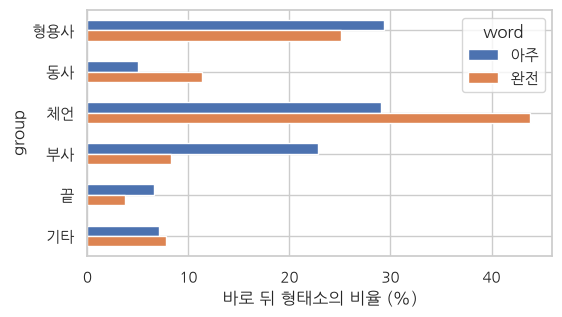

In [17]:
ax = pct.loc[order].plot.barh(figsize=(6, 3.2))
ax.invert_yaxis()
ax.set_xlabel('바로 뒤 형태소의 비율 (%)')
plt.savefig('plots/wanjeon-aju.png', dpi=150, bbox_inches='tight')

## 6. 말마다 비교하기

**둘째 물음의 답** — 두 부사는 형용사 앞에서 만나고, 명사 앞과 부사 앞에서 갈린다.

- 형용사: 둘 다 4분의 1 남짓(29.4%, 25.1%)이다. '완전'도 very로 넉넉히 쓰인다.
- 동사: '완전' 11.3%, '아주' 5.0%. 동사 앞에는 '완전'이 두 배 넘게 자주 온다.
- 체언: '완전'의 43.8%가 명사 앞이다. '완전 가을이야', '완전 공감', '완전 대박'
- 부사: '아주'의 22.8%가 부사 앞이다. '아주 잘', '아주 그냥', '아주 가끔'

'완전'이 명사 앞에 많은 것은 명사 '완전'의 오랜 자리(완전 개방)와 이어져 보인다. 다만 '완전 가을이야'의 '완전'은 명사 '가을'이 아니라 '가을이다' 전체를 꾸민다. 바로 뒤 하나만 보는 자가 놓치는 자리다.

'끝'은 조심해 읽는다. 채팅에서는 한 문장을 여러 메시지로 끊어 보낸다('와우' / '완전' / '꽁스네'). 한 발화 안에서만 바로 뒤를 찾았으므로 이런 짝은 '끝'이 된다.

이제 형용사 앞과 동사 앞에 어떤 말이 오는지 본다.

In [18]:
for g in ['형용사', '동사']:
    for w in ['완전', '아주']:
        x = a[(a['group'] == g) & (a['word'] == w)]
        print(g, w, list(x['lemma'].value_counts().index[:6]))

형용사 완전 ['좋/VA', '맛있/VA', '다르/VA', '재밌/VA', '귀엽/VA-I', '부럽/VA-I']
형용사 아주 ['좋/VA', '맛있/VA', '어리/VA', '많/VA', '멋지/VA', '귀엽/VA-I']
동사 완전 ['좋아하/VV', '웃기/VV', '빠지/VV', '맞/VV', '신나/VV', '미치/VV']
동사 아주 ['좋아하/VV', '신나/VV', '미치/VV', '죽/VV', '웃기/VV', '가/VV']


동사 앞 '완전'의 1·2위 '좋아하다'(390번)·'웃기다'(112번)는 마음의 정도를 말하니 very다. 거꾸로 형용사 앞 '완전 다르다'(161번)는 '완전히 다르다'로 바꿀 수 있는 completely다. **품사는 뜻의 어림값이다.**

**어느 쪽을 더 좋아하나.** 내용어(형용사·동사·체언·부사) 앞만 남기고, 말마다 '완전/아주'의 비를 구해 정렬한다. 비가 작을수록 '아주' 쪽, 클수록 '완전' 쪽이다.

모든 칸에 1을 더한다(**가법 평활**, add-one smoothing). '싫다'(아주 0번, 완전 41번)처럼 한쪽이 0인 말은 비가 0이나 무한대가 되고, 그러면 한 번 나온 말과 백 번 나온 말이 같은 자리에 선다. 1을 더하면 0이 사라지고, 한두 번 나온 말은 비가 1 가까이로 끌려와 **여러 번 나온 말만** 양 끝에 남는다. 더하는 수(1)도 연구자가 정한 것이니 적어 둔다.

In [19]:
c = a[a['group'].isin(['형용사', '동사', '체언', '부사'])]
ct = pd.crosstab(c['lemma'], c['word']) + 1
ct['완전/아주'] = ct['완전'] / ct['아주']
print(ct.sort_values('완전/아주').head(5))

word     아주  완전     완전/아주
lemma                    
아주/MAG   72   1  0.013889
가끔/MAG  125   5  0.040000
그냥/MAG  163   7  0.042945
잠깐/MAG   17   1  0.058824
조금/NNG   25   2  0.080000


비가 작을수록 '아주' 쪽이다. '아주 아주'(겹쳐 쓰기) 다음은 가끔, 그냥, 잠깐, 조금이다. 살짝(23 대 1), 예전(37 대 10), 어리-(43 대 25), 작-(23 대 12)도 '아주' 쪽이다(괄호 안은 1을 더하기 전의 '아주' 대 '완전'). **작은 정도, 짧은 때, 먼 옛날**이다.

정렬한 표의 맨 끝, 비가 큰 쪽을 본다.

In [20]:
print(ct.sort_values('완전/아주').tail(5))

word    아주  완전  완전/아주
lemma                
추억/NNG   1  35   35.0
가을/NNG   2  72   36.0
똑같/VA    1  36   36.0
공감/NNG   2  73   36.5
싫/VA     1  42   42.0


비가 클수록 '완전' 쪽이다. 싫-, 공감, 똑같-, 가을, 추억. 그 아래로 반대, 신기하-, 추천, 다르-(6 대 161), 대박, 웃기-가 보인다. **같음과 다름, 그리고 명사 서술어**('완전 가을이야', '완전 공감')다.

**셋째 물음의 답 — 논문과 비교해 읽으면.** '아주 조금', '아주 가끔'은 자연스럽고, 사전도 '아주'의 예문으로 '아주 가끔씩'을 든다. '아주'는 정도만 남은 very가 되어 작은 쪽의 정도까지 키운다. '완전'은 very로 널리 쓰이지만 아직 '모두, 두루'(completely)가 남아, '똑같다', '다르다'와 잘 어울리고 작은 정도와는 잘 어울리지 않는다. 논문이 말한 두 낱말의 속도 차이와 같은 쪽을 가리킨다. 이것은 수를 읽는 **한 가지 방법**이다. 수 자체가 뜻을 알려 주지는 않는다.

**드물다와 없다.** 표의 수 뒤에 있는 발화를 읽는다.

In [21]:
for f in sub.loc[sub['form'].str.contains('완전 가끔'), 'form']:
    print(f)

그래서 아빠는 완전 가끔 집에 오잖아
컴퓨터로 하는건 너무 어지러워서 못하고 핸드폰도 완전 가끔가끔해요 친구들이 그때그때 하자는거... 한 10년전에는 닌텐도 엄청 열심히했죠
으학ㅋㅋㅋ완전 가끔이예요
완전 가끔 회식때는 한잔씩 먹어욬ㅋㅋ 한모금 마시고


## 이 수가 말하지 않는 것

'완전 가끔'도 4번 있다. '아주 가끔' 124번과 비교하면 드물 뿐이다. 말뭉치는 '안 된다'를 말하지 않는다. 수는 **경향**을 보여 줄 뿐이고, 문법성은 용례를 읽고 직관과 함께 판단한다.

- **누가 썼나**: 한 사람이 '완전'을 백 번 쓰면 백 번이다. 사람마다 나누어 보지 않았다(13강).
- **누구의 말뭉치**: 화자 168,267명 가운데 여성이 87.5%, 20대가 46.5%다(11강의 화자 표).
- **분석기의 오류**: '아주스틸'은 뺐지만, '조아'(좋아)를 고유 명사로 본 것 같은 오류는 남았다.
- **바로 뒤 하나**: '완전 내 스타일'의 바로 뒤는 대명사 '내'다. 꾸밈을 받는 말은 '스타일'이다.
- **문맥**: 메시지를 끊어 보낸 짝, 앞의 말('진짜 완전')은 보지 않았다.

그래서 보고서에는 말뭉치와 판본, 분석기와 판본, 찾은 방법(`\b`, 형태소), 뺀 것('아주스틸' 49행), 묶은 방법(품사 묶음), 더한 수(1)를 적는다. 그래야 다른 사람이 같은 수를 다시 얻는다.

## 다음 시간

13강에서는 '무엇 앞에'가 아니라 '누가' 쓰는지를 센다. 11강의 `speakers.csv`를 `doc_id`와 `speaker_id` 두 열로 발화 표에 이어 붙이고, 나이와 성별로 나누어 '완전'과 '아주'의 비율을 비교한다. 10대와 40대 이상은 '완전'과 '아주'를 같은 비율로 쓸까? 화자의 87.5%가 여성인 말뭉치에서 성별을 비교할 때 무엇을 조심해야 할까?